# Module 8 Lab 2: Textbook Problem 9.1, AI-Assisted

### Grouping Countries by Savings Behavior

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

In this lab I use an AI assistant to learn a technique the course hasn't covered yet: clustering, which groups similar rows without using any labels. I work out a baseline myself, have the AI cluster 50 countries by their savings data, then check one of its claims with my own code. Every prompt I sent is logged, and the sections marked **(my own work)** are mine, not the AI's.

### The problem (Textbook 9.1)

Under the life-cycle savings hypothesis (Modigliani), a country's savings ratio depends on income per person, income growth, and how young or old the population is. The data are 1960–1970 averages for 50 countries (Belsley, Kuh & Welsch, 1980):

- `sr`: aggregate personal savings ratio
- `pop15`: % of the population under 15
- `pop75`: % of the population over 75
- `dpi`: real per-capita disposable income
- `ddpi`: % growth rate of `dpi`

**Task:** use a clustering algorithm (agglomerative and/or divisive) to find similar countries.

## Step 1: Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

savings = pd.read_csv('lifecyclesavings.csv')
savings.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


> **Note:** the country column is spelled `Contry` in this file (a typo in the original data), so the code has to use that exact name.

## Step 2: Baseline (no AI)

In [2]:
print('Shape:', savings.shape)

print('\nMissing values per column:')
print(savings.isna().sum())

print('\nMean of each numeric column:')
print(savings.mean(numeric_only=True).round(2))

Shape: (50, 6)

Missing values per column:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Mean of each numeric column:
sr          9.67
pop15      35.09
pop75       2.29
dpi      1106.76
ddpi        3.76
dtype: float64


**Baseline (my own work):**

From my baseline code:

- 50 rows (one per country) and 6 columns: `Contry` plus 5 numeric columns
- No missing values
- Means by column:
  - `sr`: 9.67
  - `pop15`: 35.09
  - `pop75`: 2.29
  - `dpi`: 1106.76
  - `ddpi`: 3.76

These overall means are what I'll compare cluster 0 against in the verification.

## Step 3: Prompt log

**Prompt 1 (sent to: Claude)**

```
You are helping me learn clustering.
My CSV (lifecyclesavings.csv, 50 rows, one per country) has columns:
  Contry (object, the country name), sr (float64), pop15 (float64),
  pop75 (float64), dpi (float64), ddpi (float64)
Write Python using pandas, scikit-learn, and matplotlib/scipy to:
(1) cluster the countries by their savings behavior using agglomerative clustering,
(2) show which countries end up in each cluster,
(3) produce one labeled chart (a dendrogram or a scatter colored by cluster).
Explain each step in comments, and tell me if the columns need scaling first.
```

- **Result:** Blocks 1–4 and the AI's explanation of the results (Step 4).
- **Fixes:**
  - Block 2: the AI drew the 3-cluster cut line at a hard-coded height of 10, but the last two merges are at about 7.3 and 15.4, so a cut at 10 really gives 2 clusters. I changed it to cut halfway between the 2nd- and 3rd-highest merges (about 7.1).
  - Block 4: the scatter used different colors than the dendrogram for the same clusters. I matched them so each cluster is the same color in both charts.
  - The other blocks ran without errors and needed no changes.
- **Check (Step 5):** Match. Cluster 0's means line up with the AI's description.
- **Things the AI said that I couldn't verify:**
  - That without scaling, `dpi` would decide almost all of the clustering. I never ran it without scaling to compare.
  - That 3 clusters is a better cut than 2. That's the AI's judgment from the dendrogram, not something I tested.
  - The descriptions of clusters 1 and 2. I only verified cluster 0.

## Step 4: The AI's code

These are the AI's blocks as it returned them, except for the two fixes listed in the prompt log. To keep the code clean, I moved its code comments into a short *AI's note* under each block heading. Its full explanation of the results is at the end of this step.

**Block 1: Scale the columns**

*AI's note:* the columns need scaling first. `dpi` is in the hundreds to thousands while `pop75` is around 1 to 5, so without scaling `dpi` would decide almost everything. `StandardScaler` turns each column into "how many standard deviations from the mean," so every column counts equally.

In [3]:
from sklearn.preprocessing import StandardScaler

features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X_scaled = StandardScaler().fit_transform(savings[features])

print('Scaled data shape:', X_scaled.shape)
print('Column means after scaling (should be ~0):', X_scaled.mean(axis=0).round(2))
print('Column std after scaling (should be 1):  ', X_scaled.std(axis=0).round(2))

Scaled data shape: (50, 5)
Column means after scaling (should be ~0): [ 0. -0. -0. -0. -0.]
Column std after scaling (should be 1):   [1. 1. 1. 1. 1.]


**Block 2: Dendrogram**

*AI's note:* agglomerative clustering starts with every country as its own group and keeps merging the two closest groups. The height of each merge shows how different the two groups were, and a big vertical jump is a natural place to cut. The dashed line is the 3-cluster cut.

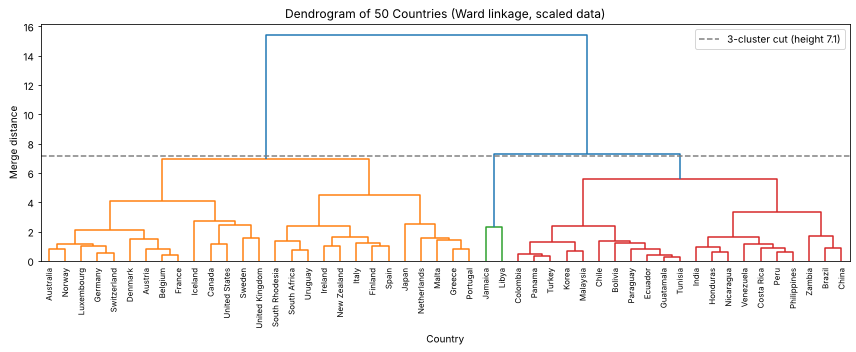

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method='ward')
cut = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(Z, labels=savings['Contry'].tolist(), leaf_rotation=90, leaf_font_size=8,
           color_threshold=cut)
plt.axhline(y=cut, color='gray', linestyle='--', label=f'3-cluster cut (height {cut:.1f})')
plt.legend()
plt.title('Dendrogram of 50 Countries (Ward linkage, scaled data)')
plt.xlabel('Country')
plt.ylabel('Merge distance')
plt.tight_layout()
plt.show()

**Block 3: Three clusters and who is in them**

*AI's note:* the biggest jump in the dendrogram suggests 2 main groups. Cutting at 3 keeps those 2 and also splits off a very small third group, so the unusual countries are visible instead of hidden.

In [5]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=3, linkage='ward')
savings['cluster'] = model.fit_predict(X_scaled)

for c in sorted(savings['cluster'].unique()):
    members = savings.loc[savings['cluster'] == c, 'Contry'].tolist()
    print(f'Cluster {c} ({len(members)} countries):')
    print('  ' + ', '.join(members))
    print()

Cluster 0 (27 countries):
  Australia, Austria, Belgium, Canada, Denmark, Finland, France, Germany, Greece, Iceland, Ireland, Italy, Japan, Luxembourg, Malta, Norway, Netherlands, New Zealand, Portugal, South Africa, South Rhodesia, Spain, Sweden, Switzerland, United Kingdom, United States, Uruguay

Cluster 1 (21 countries):
  Bolivia, Brazil, Chile, China, Colombia, Costa Rica, Ecuador, Guatamala, Honduras, India, Korea, Nicaragua, Panama, Paraguay, Peru, Philippines, Turkey, Tunisia, Venezuela, Zambia, Malaysia

Cluster 2 (2 countries):
  Jamaica, Libya



**Block 4: Scatter colored by cluster**

*AI's note:* `pop15` vs. `dpi` shows the split between young, poorer countries and older, richer ones most clearly.

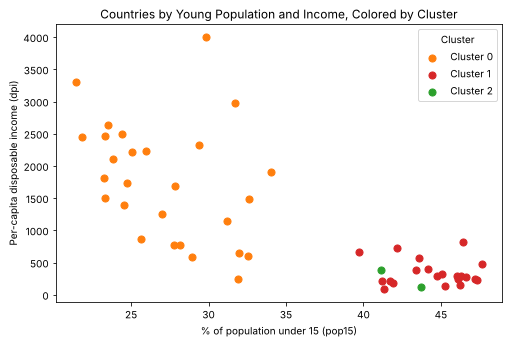

In [6]:
cluster_colors = {0: 'C1', 1: 'C3', 2: 'C2'}

plt.figure(figsize=(8, 5))
for c in sorted(savings['cluster'].unique()):
    group = savings[savings['cluster'] == c]
    plt.scatter(group['pop15'], group['dpi'], label=f'Cluster {c}', s=50, color=cluster_colors[c])

plt.title('Countries by Young Population and Income, Colored by Cluster')
plt.xlabel('% of population under 15 (pop15)')
plt.ylabel('Per-capita disposable income (dpi)')
plt.legend(title='Cluster')
plt.show()

**The AI's explanation of the results:**

- **Scaling:** The columns were scaled first because `dpi` is in the hundreds to thousands while `pop75` is around 1 to 5. Without scaling, income would decide almost all of the clustering.
- **Method:** Agglomerative clustering with Ward linkage starts with each country on its own and keeps merging the two closest groups, picking the merge that adds the least spread inside the groups.
- **How many clusters:** The biggest jump in the dendrogram suggests 2 main groups. Cutting at 3 keeps those 2 and also separates a small group of unusual countries.
- **Cluster 0 (27 countries):** richer countries with older populations: higher `dpi`, lower `pop15`, higher `pop75`, and the highest savings ratio (`sr`) of the three clusters.
- **Cluster 1 (21 countries):** poorer countries with young populations: low `dpi`, high `pop15`, and lower savings.
- **Cluster 2 (2 countries, Jamaica and Libya):** similar to cluster 1 on income and age, but their income growth (`ddpi`) is far higher than everyone else's, which is why they get their own cluster.

## Step 5: Verification

I picked cluster 0, computed its means with my own `groupby`, and put them next to the overall means from my baseline. I also printed the savings ratio for all three clusters to check the AI's "highest savings" claim.

In [7]:
cluster_means = savings.groupby('cluster')[features].mean()
cluster_0_means = cluster_means.loc[0]
overall_means = savings[features].mean()

comparison_df = pd.DataFrame({
    'cluster 0': cluster_0_means,
    'overall': overall_means
})

print('Cluster 0 vs. overall means:')
print(comparison_df.round(2))

print('\nSavings ratio (sr) by cluster:')
print(cluster_means['sr'].round(2))

Cluster 0 vs. overall means:
       cluster 0  overall
sr         11.60     9.67
pop15      27.24    35.09
pop75       3.31     2.29
dpi      1763.29  1106.76
ddpi        3.79     3.76

Savings ratio (sr) by cluster:
cluster
0    11.60
1     7.33
2     8.30
Name: sr, dtype: float64


**Verification (my own work):**

The AI's clusters hold up. I checked cluster 0 against the overall means, and it matches what the AI described: higher income (`dpi` 1763 vs. 1107), an older population (lower `pop15`, higher `pop75`), and a higher savings ratio (11.6 vs. 9.67), which is also the highest of the three clusters. What concerns me is that the AI's explanation used words like "richer," "older," and "highest savings" but never showed the numbers behind them, so I had to compute them myself. My prompt probably should have asked for a summary table of each cluster. Overall it's a match, but the AI didn't back up its claims with data.

## Step 6: Interpretation and caution

**Interpretation and caution (my own work):**

The AI broke the data into three clusters of different sizes. The algorithm looked at all 5 columns and grouped similar countries together. Cluster 0 (27 countries) has the richer countries with more savings and older populations, and cluster 1 (21 countries) has poorer countries with less savings and more young people. The last cluster has only two countries, Jamaica and Libya, which don't really fit either group because their income growth is much higher than everyone else's (10.2% and 16.7%, while most countries are around 3%). Overall, the cluster breakdown makes sense.

I would be careful trusting an AI with a technique I don't fully understand yet. In this project the clustering worked, but since I've never used clustering before, it would be hard for me to catch a mistake. For example, the AI's first version of the dendrogram drew the cut line in the wrong place, and that's an easy mistake to miss when you don't know the method yet.

## Step 7: Reproducibility

Restart and Run All in Jupyter (VS Code) finishes top to bottom with no errors, using only `lifecyclesavings.csv` from the same folder. The notebook is pushed to `module8/`.